# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose



## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [16]:
# Run this code:

df = pd.read_csv("https://raw.githubusercontent.com/Dee-M123/lab-time-series/refs/heads/main/data/sub_1.csv")
df.drop(columns=['Unnamed: 0'], inplace=True)

In [17]:
df.head()

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
3,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958
4,1.493941,-0.703918,0.672994,0.760062,0.647210,-0.058530,0.114253,-0.912890,0.047341,0.199441,0.353996,-0.044299


Examine the data using the `head` function.

In [18]:
df.columns


Index(['attitude.roll', 'attitude.pitch', 'attitude.yaw', 'gravity.x',
       'gravity.y', 'gravity.z', 'rotationRate.x', 'rotationRate.y',
       'rotationRate.z', 'userAcceleration.x', 'userAcceleration.y',
       'userAcceleration.z'],
      dtype='object')

Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [19]:
df.isnull().sum()



,0
attitude.roll,0
attitude.pitch,0
attitude.yaw,0
gravity.x,0
gravity.y,0
gravity.z,0
rotationRate.x,0
rotationRate.y,0
rotationRate.z,0
userAcceleration.x,0


How many rows and columns are in our data?

In [20]:
df.shape



(1751, 12)

To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [21]:
df["time"] = pd.date_range(
    start="2018-01-01 00:00:00",
    end="2018-01-01 00:29:10",
    periods=len(df))



Assign the time series index to the dataframe's index.

In [31]:
user_x = df.set_index("time")["userAcceleration.x"]

user_x



,userAcceleration.x
time,
2018-01-01 00:00:00,0.294894
2018-01-01 00:00:01,0.219405
2018-01-01 00:00:02,0.010714
2018-01-01 00:00:03,-0.008389
2018-01-01 00:00:04,0.199441
...,...
2018-01-01 00:29:06,-0.268367
2018-01-01 00:29:07,-0.102444
2018-01-01 00:29:08,-0.085590


Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

In [36]:
decomposition_x = seasonal_decompose(user_x, period=60)






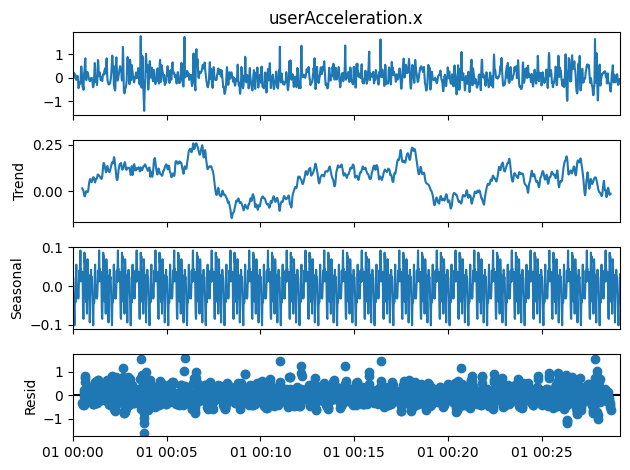

In [37]:
decomposition_x.plot()
plt.show()

Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

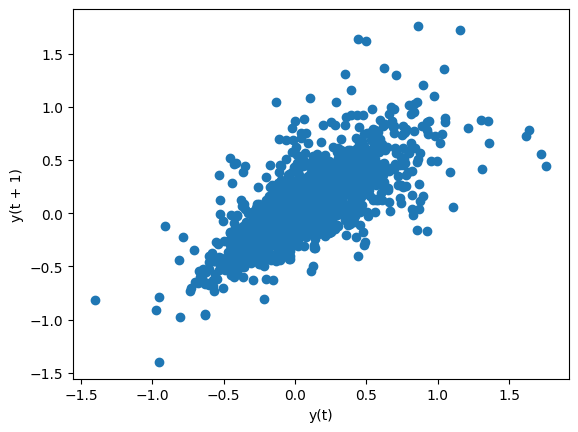

In [38]:
from pandas.plotting import lag_plot

lag_plot(user_x)
plt.show()

Create a lag plot for `rotationRate.x`

In [39]:
rotation_x = df.set_index("time")["rotationRate.x"]


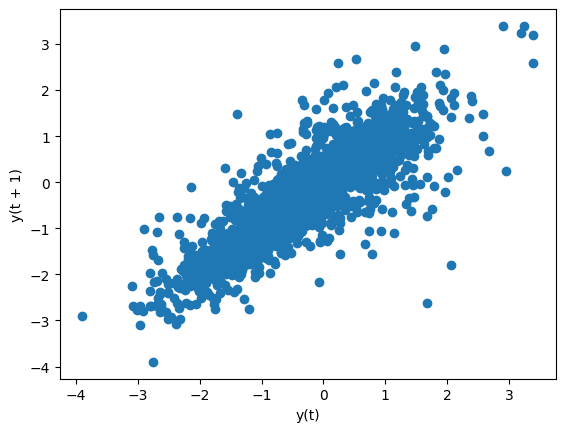

In [40]:
lag_plot(rotation_x)
plt.show()

What are your conclusions from both visualizations?

In [26]:
# Both userAcceleration.x and rotationRate.x show strong autocorrelation: they are not independent


The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [41]:
from statsmodels.tsa.stattools import adfuller

# userAcceleration.x
adf_user = adfuller(user_x)

# rotationRate.x
rotation_x = df.set_index("time")["rotationRate.x"]
adf_rotation = adfuller(rotation_x)



In [42]:
print("userAcceleration.x ADF p-value:", adf_user[1])
print("rotationRate.x ADF p-value:", adf_rotation[1])

userAcceleration.x ADF p-value: 2.823439483037483e-30
rotationRate.x ADF p-value: 6.320230335912449e-06


What are your conclusions from this test?

In [28]:
# Both are stationary



Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set.

In [43]:
from statsmodels.tsa.arima.model import ARIMA

# last 10 = test
train = user_x[:-10]
test = user_x[-10:]


In [44]:
model = ARIMA(train, order=(2, 0, 1))  # (p, d, q)
model_fit = model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


In [45]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:     userAcceleration.x   No. Observations:                 1741
Model:                 ARIMA(2, 0, 1)   Log Likelihood                 373.401
Date:                Wed, 18 Mar 2026   AIC                           -736.803
Time:                        14:21:45   BIC                           -709.492
Sample:                    01-01-2018   HQIC                          -726.704
                         - 01-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.0

To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [46]:
from statsmodels.tools.eval_measures import rmse

predictions = model_fit.forecast(steps=10)



In [47]:
error = rmse(test, predictions)
print("RMSE:", error)

RMSE: 0.2252916045020626
